<a href="https://colab.research.google.com/github/EstherMan05/ds2002-fa26/blob/main/2026_11_13_%E2%80%94_Visualization_Challenge_%E2%80%94_Lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# DS2002 · Visualization Challenge

**Lab — 2026-11-13 · Fall 2026**  

---

## Lab 11 — Visualization Challenge

Five charts from the **same game-day sample** as Monday's lecture. Each one is graded against the **six-point rubric** from Wednesday's studio — use `score()` from that notebook or re-type it here.

| # | Criterion |
|---|---|
| 1 | Title states a finding, not a topic |
| 2 | Axes labeled with units |
| 3 | Right chart type for the question |
| 4 | Honest scale |
| 5 | Readable — sorted, no clipping, no overlap |
| 6 | No wasted ink |

Every chart needs a one-line **caption** below it saying what decision it supports.

**Due Wednesday, November 18, 11:59pm ET** in Canvas (pushed back one week for midterm presentations). Use Monday's recipes (`barh`, `lineplot`, `histplot`, `finish()`, etc.) — you do not need new chart types beyond what the cookbook already showed.

In [ ]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

BLUE, RUST, GRAY = '#4a5d7e', '#b4553f', '#c9d0d9'
sns.set_theme(style='white')
plt.rcParams['text.parse_math'] = False

CRITERIA = [
    'title states a finding',
    'axes labeled with units',
    'right chart for the question',
    'honest scale',
    'readable',
    'no wasted ink',
]

def score(**passed):
    """score(title=False, axes=True, ...) -> prints a scored critique."""
    total = 0
    for name, ok in zip(CRITERIA, passed.values()):
        print(('PASS' if ok else 'FAIL'), '-', name)
        total += bool(ok)
    print(f'\nscore: {total}/6')
    return total


def finish(ax, title, xlabel=None, ylabel=None, fontsize=12):
    """Same helper as Monday's lecture: title, labels, spines, tight_layout."""
    ax.set_title(title, loc='left', fontsize=fontsize)
    if xlabel is not None:
        ax.set_xlabel(xlabel)
    if ylabel is not None:
        ax.set_ylabel(ylabel)
    for spine in ('top', 'right'):
        ax.spines[spine].set_visible(False)
    ax.figure.tight_layout()


# --- game-day sample (same generator as the Monday lecture) ------------------
rng = np.random.default_rng(2026)
hours = np.arange(9, 22)
build_up = np.exp(-((hours - 14.5) ** 2) / (2 * 2.3 ** 2))
storm = np.exp(-((hours - 17.0) ** 2) / (2 * 1.5 ** 2))
GAMES = {'Sep 5': False, 'Sep 19': False, 'Oct 10': True, 'Nov 14': True}

rows = []
for game, rainy in GAMES.items():
    rain_mm = rainy * (0.4 + 3.0 * storm) * rng.gamma(10, 0.1, len(hours))
    for h, b, rain in zip(hours, build_up, rain_mm):
        n_main = rng.poisson(b * 150 + 12)
        n_rain = rng.poisson(rain * 5 + 0.2)
        cats = np.concatenate([
            rng.choice(['Food', 'Merch', 'Drink'], n_main, p=[.45, .22, .33]),
            np.repeat('RainGear', n_rain),
        ])
        rows += [(game, 'rain' if rainy else 'dry', h, round(rain, 1), c) for c in cats]

df = pd.DataFrame(rows, columns=['game', 'weather', 'hour', 'rain_mm', 'category'])
df['zone'] = rng.choice(['A', 'B', 'C'], len(df), p=[.6, .3, .1])
df['revenue'] = (
    df['category'].map({'Food': 12, 'Merch': 28, 'Drink': 6, 'RainGear': 15})
    * rng.lognormal(-0.18, 0.6, len(df))
).round(2)

print(len(df), 'orders across', df['game'].nunique(), 'games')
df.head()


4364 orders across 4 games


,game,weather,hour,rain_mm,category,zone,revenue
0,Sep 5,dry,9,0.0,Food,C,7.90
1,Sep 5,dry,9,0.0,Food,B,5.46
2,Sep 5,dry,9,0.0,Drink,A,7.93
3,Sep 5,dry,9,0.0,Drink,B,5.68
4,Sep 5,dry,9,0.0,Merch,A,12.75


### Chart 1 — revenue by category

Sorted horizontal bar. Axis from zero.

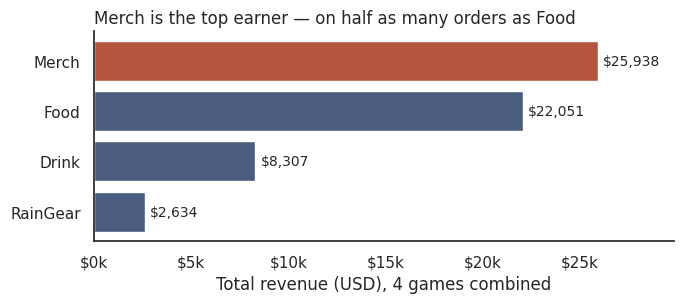

In [ ]:
cat_rev = df.groupby('category')['revenue'].sum().sort_values()
n_games = df['game'].nunique()

fig, ax = plt.subplots(figsize=(7, 3.2))
colors = [RUST if c == 'Merch' else BLUE for c in cat_rev.index]
ax.barh(cat_rev.index, cat_rev.values, color=colors)
ax.set_xlim(0, cat_rev.max() * 1.15)
for y, v in enumerate(cat_rev.values):
    ax.text(v + cat_rev.max() * 0.01, y, f'${v:,.0f}', va='center', fontsize=10)
ax.xaxis.set_major_formatter(lambda x, _: f'${x/1000:.0f}k')
finish(ax, 'Merch is the top earner — on half as many orders as Food',
       xlabel='Total revenue (USD), 4 games combined')
ax.set_ylabel('')
plt.show()

**Caption:** Decision: give Merch prime stand space and inventory priority, it is the largest revenue line (\$25.9k) even though Food sells about twice as many orders.

### Chart 2 — revenue by hour

Line chart, kickoff marked at 15.5, and the title should state the staffing implication rather than describing the axes.

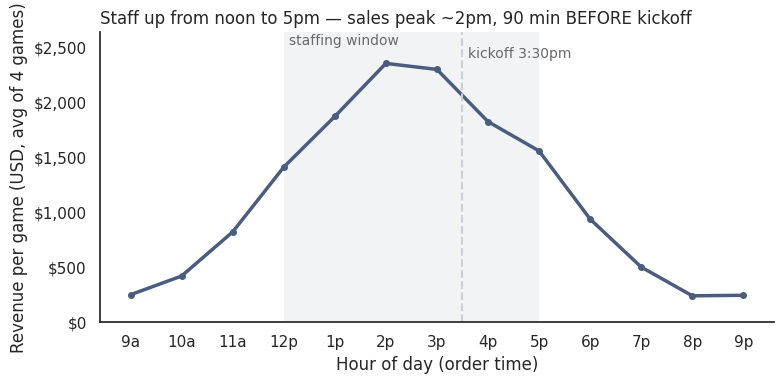

In [ ]:
by_hour = df.groupby('hour')['revenue'].sum() / df['game'].nunique()   # avg $ per game

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(by_hour.index, by_hour.values, color=BLUE, lw=2.5, marker='o', ms=4)
ax.axvline(15.5, color=GRAY, ls='--', lw=1.5)
ax.text(15.6, by_hour.max() * 1.02, 'kickoff 3:30pm', color='dimgray', fontsize=10)
ax.axvspan(12, 17, color=GRAY, alpha=0.25, lw=0)
ax.text(12.1, by_hour.max() * 1.07, 'staffing window', color='dimgray', fontsize=10)
ax.set_ylim(0, by_hour.max() * 1.12)
ax.set_xticks(hours)
ax.set_xticklabels([f'{h % 12 or 12}{"a" if h < 12 else "p"}' for h in hours])
ax.yaxis.set_major_formatter(lambda y, _: f'${y:,.0f}')
finish(ax, 'Staff up from noon to 5pm — sales peak ~2pm, 90 min BEFORE kickoff',
       xlabel='Hour of day (order time)', ylabel='Revenue per game (USD, avg of 4 games)')
plt.show()

**Caption:** Decision: schedule the full concessions crew from noon to 5pm. Sales peak at 2–3pm, roughly 90 minutes before the 3:30 kickoff, so being fully staffed before the game matters more than staffing late into it.

### Chart 3 — revenue by zone, normalized

Raw revenue by zone mostly measures how big each zone is. Use the capacity figures below to build a second view — revenue per unit of capacity — and show both side by side.

Then say which of the two you would put in front of a manager, and for which question.

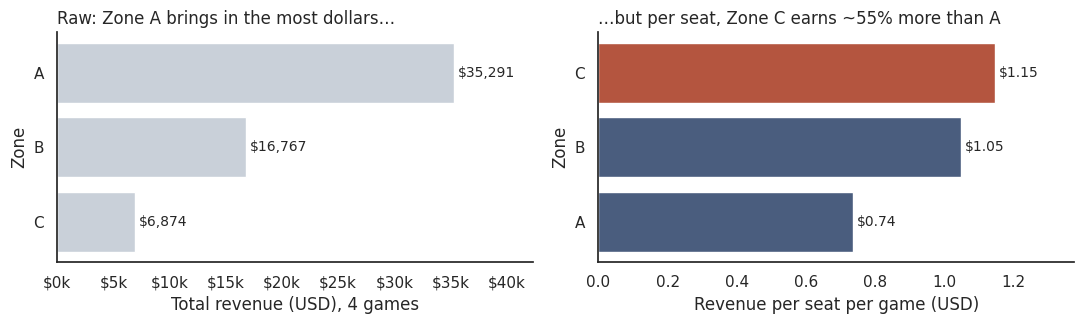

In [ ]:
zone_capacity = {'A': 12000, 'B': 4000, 'C': 1500}
n_games = df['game'].nunique()
zone = df.groupby('zone')['revenue'].sum().to_frame('raw')
zone['capacity'] = pd.Series(zone_capacity)
zone['per_seat'] = zone['raw'] / zone['capacity'] / n_games     # $ per seat per game

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 3.4))
raw = zone['raw'].sort_values()
ax1.barh(raw.index, raw.values, color=GRAY)
ax1.set_xlim(0, raw.max() * 1.2)
for y, v in enumerate(raw.values):
    ax1.text(v + raw.max() * 0.01, y, f'${v:,.0f}', va='center', fontsize=10)
ax1.xaxis.set_major_formatter(lambda x, _: f'${x/1000:.0f}k')
finish(ax1, 'Raw: Zone A brings in the most dollars…', xlabel='Total revenue (USD), 4 games', ylabel='Zone')

per = zone['per_seat'].sort_values()
ax2.barh(per.index, per.values, color=[RUST if z == 'C' else BLUE for z in per.index])
ax2.set_xlim(0, per.max() * 1.2)
for y, v in enumerate(per.values):
    ax2.text(v + per.max() * 0.01, y, f'${v:.2f}', va='center', fontsize=10)
finish(ax2, '…but per seat, Zone C earns ~55% more than A',
       xlabel='Revenue per seat per game (USD)', ylabel='Zone')
plt.show()

**Caption, and which panel I would present**:Decision: where to add the next stand or extra staff. For that question I would put the per-seat panel in front of a manager: Zone C earns \$1.15 per seat per game and Zone A only \$0.74, which suggests A's fans are under-served (long lines, too few stands) rather than A being the strongest zone. For a different question (budgeting, inventory volume, or which zone we can least afford to have go down) I would show the raw panel, since Zone A still brings in about 60% of all revenue._

### Chart 4 — distribution, not just totals

Every chart so far is a total. **TODO:** show the *distribution* of individual order revenue with a histogram. What does the shape tell you that a category total does not?

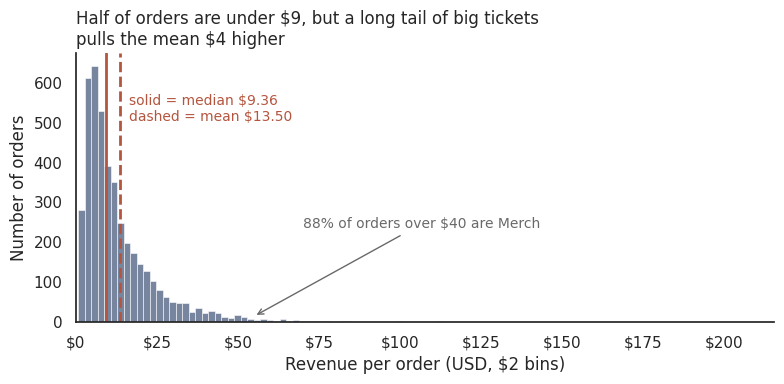

In [ ]:
med, mean = df['revenue'].median(), df['revenue'].mean()
big = df[df['revenue'] > 40]
merch_share_big = (big['category'] == 'Merch').mean()

fig, ax = plt.subplots(figsize=(8, 4))
sns.histplot(df['revenue'], binwidth=2, color=BLUE, edgecolor='white', ax=ax)
ax.axvline(med, color=RUST, lw=2)
ax.axvline(mean, color=RUST, lw=2, ls='--')
top = ax.get_ylim()[1]
ax.text(mean + 3, top * 0.85, f'solid = median ${med:.2f}\ndashed = mean ${mean:.2f}',
        color=RUST, fontsize=10, va='top')
ax.annotate(f'{merch_share_big:.0%} of orders over $40 are Merch', xy=(55, 15), xytext=(70, top * 0.35),
            fontsize=10, color='dimgray', arrowprops=dict(arrowstyle='->', color='dimgray'))
ax.set_xlim(0, df['revenue'].max() * 1.02)
ax.xaxis.set_major_formatter(lambda x, _: f'${x:.0f}')
finish(ax, f'Half of orders are under ${med:.0f}, but a long tail of big tickets\npulls the mean ${mean - med:.0f} higher',
       xlabel='Revenue per order (USD, $2 bins)', ylabel='Number of orders')
plt.show()

**Caption:** Decision: plan pricing and promotions around the typical ~\$9 order (for example, bundles that push it toward \$15) instead of the \$13.50 mean. The shape shows what a category total hides: revenue is right-skewed. Most orders are small Food and Drink purchases, and the big-ticket tail is almost all Merch (88% of orders over \$40), so a handful of Merch sales can swing the totals.

### Chart 5 — your choice

**TODO:** a grouped, stacked, or scatter view that reveals something the first four do not. The finding is the point; the chart type is your call.

If you use a scatter, size or annotate the points so a reader can tell which ones carry enough data to trust.

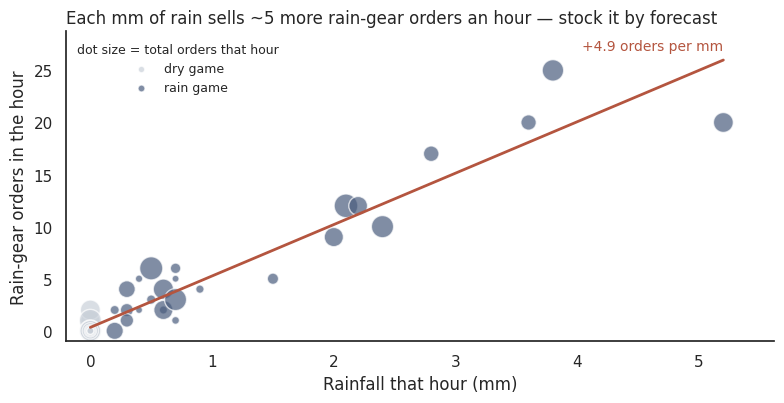

In [ ]:
gh = (df.assign(is_rg=df['category'].eq('RainGear'))
        .groupby(['game', 'hour'])
        .agg(rain_mm=('rain_mm', 'first'), weather=('weather', 'first'),
             rg_orders=('is_rg', 'sum'), orders=('revenue', 'size'))
        .reset_index())
slope, intercept = np.polyfit(gh['rain_mm'], gh['rg_orders'], 1)

fig, ax = plt.subplots(figsize=(8, 4.2))
for w, color in [('dry', GRAY), ('rain', BLUE)]:
    sub = gh[gh['weather'] == w]
    ax.scatter(sub['rain_mm'], sub['rg_orders'], s=sub['orders'] * 1.5, color=color,
               alpha=0.7, edgecolor='white', label=f'{w} game')
xs = np.linspace(0, gh['rain_mm'].max(), 50)
ax.plot(xs, slope * xs + intercept, color=RUST, lw=2)
ax.text(xs[-1], slope * xs[-1] + intercept + 1, f'+{slope:.1f} orders per mm',
        color=RUST, ha='right', fontsize=10)
ax.set_xlim(-0.2, gh['rain_mm'].max() * 1.08)
ax.set_ylim(-1, gh['rg_orders'].max() * 1.15)
ax.legend(frameon=False, loc='upper left', title='dot size = total orders that hour',
          title_fontsize=9, fontsize=9, markerscale=0.4)
finish(ax, f'Each mm of rain sells ~{slope:.0f} more rain-gear orders an hour — stock it by forecast',
       xlabel='Rainfall that hour (mm)', ylabel='Rain-gear orders in the hour')
plt.show()

**Caption:** Decision: tie rain-gear stock and stand placement to the hourly forecast. Each mm of rain adds about 5 rain-gear orders per hour, and dry games sell almost none. Dot size is total orders that hour; the heavy-rain points each sit on 80–190 orders, so thin hours aren't driving the trend.

### Score your own work

**TODO:** score each chart out of 6 and fix anything under 5 before submitting.

In [ ]:
# score(title, axes, chart_type, honest_scale, readable, no_wasted_ink)
print('--- chart 1'); s1 = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)
print('--- chart 2'); s2 = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)
print('--- chart 3'); s3 = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=True)
# chart 4: the empty tail past ~$100 is mostly blank space, but cutting it would hide the largest orders
print('--- chart 4'); s4 = score(title=True, axes=True, chart=True, scale=True, readable=True, ink=False)
# chart 5: dots in the low-rain cluster (0-1 mm) overlap a bit even with transparency
print('--- chart 5'); s5 = score(title=True, axes=True, chart=True, scale=True, readable=False, ink=True)
print()

scores = {
    'chart 1 (category)': s1,
    'chart 2 (hour)': s2,
    'chart 3 (zone)': s3,
    'chart 4 (distribution)': s4,
    'chart 5 (your choice)': s5,
}

for name, s in scores.items():
    status = 'unscored' if s is None else ('fix' if s < 5 else 'ok')
    print(f'{name:<26} {s}/6  [{status}]')

filled = [s for s in scores.values() if s is not None]
if filled:
    print(f'\naverage: {sum(filled) / len(filled):.1f}/6')

--- chart 1
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6
--- chart 2
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6
--- chart 3
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
PASS - no wasted ink

score: 6/6
--- chart 4
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
PASS - readable
FAIL - no wasted ink

score: 5/6
--- chart 5
PASS - title states a finding
PASS - axes labeled with units
PASS - right chart for the question
PASS - honest scale
FAIL - readable
PASS - no wasted ink

score: 5/6

chart 1 (category)         6/6  [ok]
chart 2 (hour)             6/6  [ok]
chart 3 (zone)             6/6  [ok

### Write-up

**a)** Which chart changed your mind about something in the data? If none did, which was hardest to title, and why?

**b)** Chart 3 gave you two defensible views of the same data. Explain the situation in which each one is the right one to show.

**a)** Chart 3 changed my mind. From the raw totals I assumed Zone A was the strongest zone and the obvious place to invest. Normalizing by capacity flipped tha, Zone A earns the least per seat (\$0.74 per game vs. \$1.15 in Zone C). Its big total comes from size, not from fans spending more, so A may actually be under-served. Chart 2 was the hardest to title. The easy title ("revenue by hour") just describes the axes, and turning it into a staffing call meant deciding where the window starts and ends. Doing that is how I noticed the peak lands about 90 minutes before kickoff, not during the game.

**b)** Raw revenue is the right view when the question is about scale, budgeting, how much inventory to send where, or which zone we can least afford to have a stand go down in. Zone A brings in about 60% of the money, so it gets protected first. Revenue per unit of capacity is the right view when the question is about efficiency or where the next investment goes, like adding a stand, more staff, or a new menu item. It takes zone size out of the picture and shows where each seat spends more. Using raw totals to answer an efficiency question would just reward the biggest zone for being big.